# QUPATH hand-crafted features + Random Forest



This notebook reproduces **QuPath** (Bankhead et al. 2017) and surveyed in **Gurcan et al. 2009** —
entirely in Python, no GUI:

1. **Tissue detection** — Otsu threshold on saturation
2. **Color deconvolution** — separate H&E into hematoxylin (nuclei) / eosin (stroma)
3. **Watershed nuclei segmentation** — the classic hand-engineered detector
4. **Hand-crafted features** — Haralick/GLCM texture + nuclei density + colour
5. **Random Forest** — the classical classifier → a whole-slide tumour-cellularity map

Run top-to-bottom (**Run All**). Point `SLIDE` at your downloaded `.svs`.

In [ ]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import openslide
from skimage.color import rgb2hed, rgb2hsv, label2rgb
from skimage.filters import threshold_otsu
from skimage.feature import graycomatrix, graycoprops, peak_local_max
from skimage.segmentation import watershed
from skimage.measure import regionprops
from scipy import ndimage as ndi
from sklearn.ensemble import RandomForestClassifier

# Point this at the downloaded slide. We check a couple of likely spots
# and use the first one that exists.
possible_paths = [
    os.path.expanduser("~/wsi-shared-slides/TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.svs"),
    "data/TCGA-AR-A0TP.svs",
]
SLIDE = None
for path in possible_paths:
    if os.path.exists(path):
        SLIDE = path
        break
assert SLIDE, "Slide not found - see data/download_slides.md"

s = openslide.OpenSlide(SLIDE)
print("opened:", os.path.basename(SLIDE))
print("level-0:", s.dimensions,
      "| mpp:", s.properties.get("openslide.mpp-x"),
      "| mag:", s.properties.get("openslide.objective-power"))

opened: TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.svs
level-0: (75208, 83190) | mpp: 0.24679999999999999 | mag: 40


## 1. Tissue detection (Otsu on saturation)

thumbnail (5199, 4700)  |  tissue fraction 43.6%


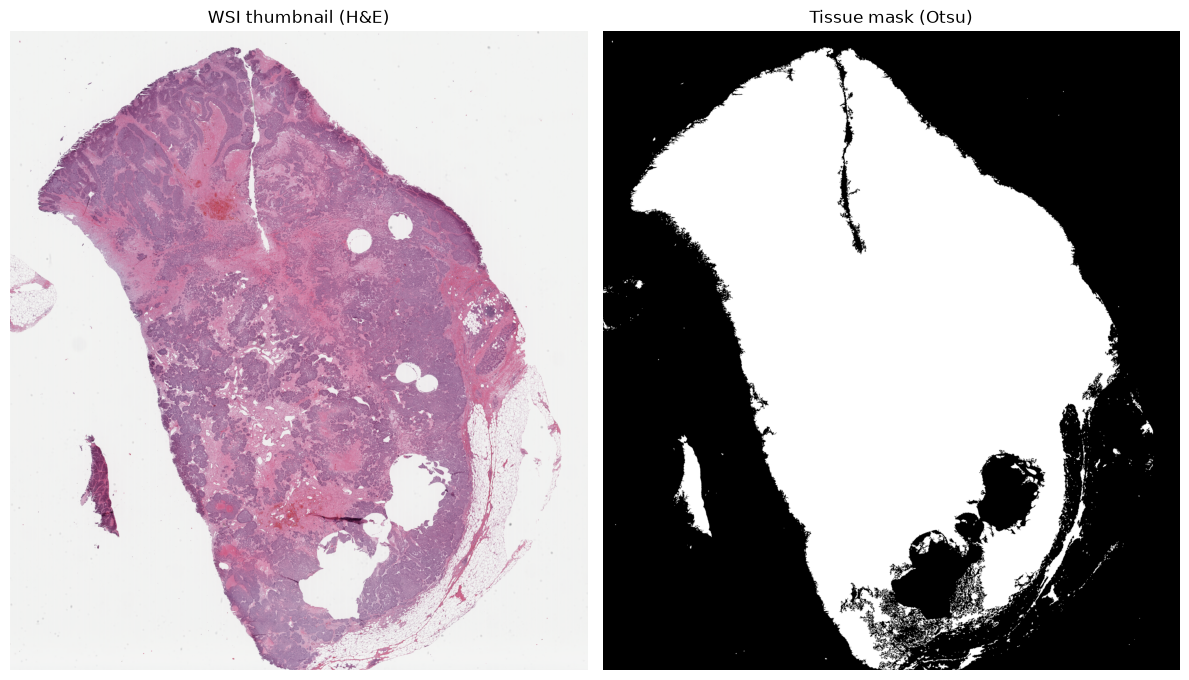

In [ ]:
LV = 2                                        # low-res level (~16x downsample)
W, H = s.level_dimensions[LV]
thumb = np.array(s.read_region((0, 0), LV, (W, H)).convert("RGB"))

# Tissue = the colourful (saturated) pixels; background is white/grey.
sat = rgb2hsv(thumb)[:, :, 1]
tissue = sat > threshold_otsu(sat)
tissue = ndi.binary_fill_holes(ndi.binary_opening(tissue, iterations=2))
print(f"thumbnail {thumb.shape[:2]}  |  tissue fraction {tissue.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 7))
ax[0].imshow(thumb)
ax[0].set_title("WSI thumbnail (H&E)")
ax[0].axis("off")
ax[1].imshow(tissue, cmap="gray")
ax[1].set_title("Tissue mask (Otsu)")
ax[1].axis("off")
plt.tight_layout()
plt.show()

## 2. Colour deconvolution — H&E → hematoxylin + eosin
The 2001 Ruifrok & Johnston method: unmix the stains so nuclei (hematoxylin) and
stroma/cytoplasm (eosin) live in separate channels.

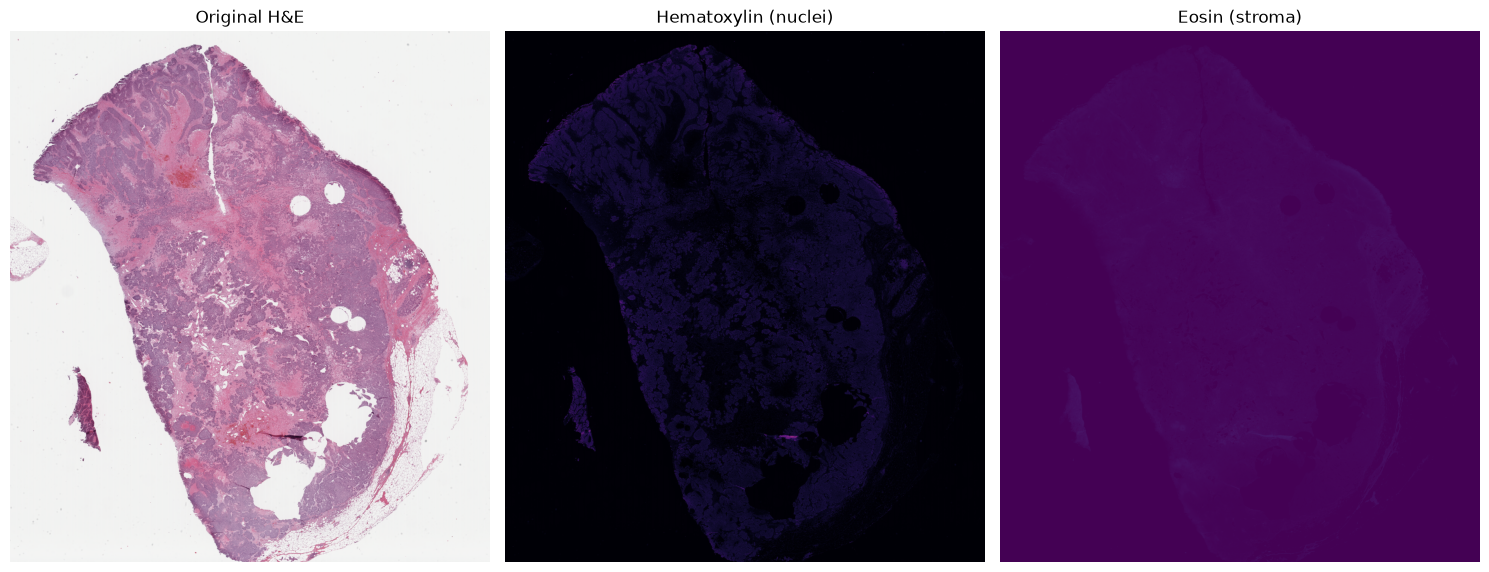

In [ ]:
hed = rgb2hed(thumb)
hema_full = hed[:, :, 0]      # hematoxylin channel -> nuclei
eos_full = hed[:, :, 1]       # eosin channel -> stroma / cytoplasm
hema_thr = threshold_otsu(hema_full[tissue])

fig, ax = plt.subplots(1, 3, figsize=(15, 6))
ax[0].imshow(thumb)
ax[0].set_title("Original H&E")
ax[0].axis("off")
ax[1].imshow(hema_full, cmap="magma")
ax[1].set_title("Hematoxylin (nuclei)")
ax[1].axis("off")
ax[2].imshow(eos_full, cmap="viridis")
ax[2].set_title("Eosin (stroma)")
ax[2].axis("off")
plt.tight_layout()
plt.show()

## 3. Hand-crafted feature extraction over tiles
For every tissue tile: **Haralick/GLCM texture** (contrast, homogeneity, energy,
correlation, ASM), a **nuclei-density** proxy (fraction of hematoxylin-positive pixels),
and mean **R/G/B colour**. These are exactly the descriptors the classical era relied on.

In [ ]:
TILE = 64                                     # 64 px @ lvl2 ~ 1024 px @ 40x
gray = (rgb2hsv(thumb)[:, :, 2] * 255).astype(np.uint8)
FEAT_NAMES = ["contrast", "homogeneity", "energy", "correlation", "ASM",
              "nuclei_density", "mean_R", "mean_G", "mean_B"]


def tile_features(y, x):
    """Return the 9 hand-crafted features for the tile at (y, x)."""
    # Haralick / GLCM texture on the greyscale tile (reduced to 8 grey levels)
    g = gray[y:y+TILE, x:x+TILE] // 32
    glcm = graycomatrix(g, [1], [0], levels=8, symmetric=True, normed=True)
    texture = [graycoprops(glcm, p)[0, 0]
               for p in ("contrast", "homogeneity", "energy", "correlation", "ASM")]
    # nuclei density = fraction of hematoxylin-positive pixels
    density = (hema_full[y:y+TILE, x:x+TILE] > hema_thr).mean()
    # mean R / G / B colour
    colour = [thumb[y:y+TILE, x:x+TILE, ch].mean() for ch in range(3)]
    return texture + [density] + colour


feats, coords = [], []
t0 = time.time()
for y in range(0, H - TILE, TILE):
    for x in range(0, W - TILE, TILE):
        # skip tiles that are mostly background
        if tissue[y:y+TILE, x:x+TILE].mean() < 0.5:
            continue
        feats.append(tile_features(y, x))
        coords.append((y, x))

feats = np.array(feats)
coords = np.array(coords)
dens = feats[:, FEAT_NAMES.index("nuclei_density")]   # pull the density column back out
print(f"{len(feats)} tissue tiles x {feats.shape[1]} hand-crafted features  ({time.time()-t0:.1f}s)")

2592 tissue tiles x 9 hand-crafted features  (0.3s)


## 4. Watershed nuclei segmentation (high-res close-up)
The signature classical detector: threshold the hematoxylin channel, then split touching
nuclei with a distance-transform **watershed**. Shown on the most cellular tile at full 40x.

1778 nuclei | median area 118px | median eccentricity 0.75


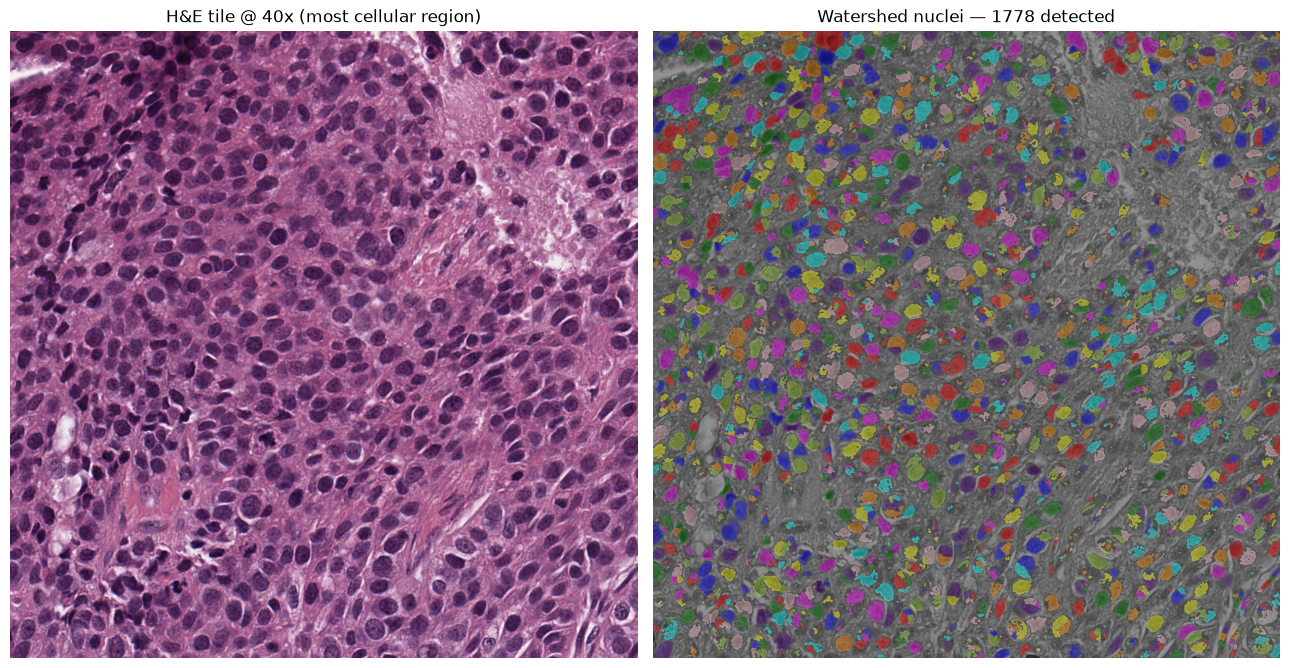

In [ ]:
# Find the most cellular tile and read it at full 40x resolution
yi, xi = coords[int(np.argmax(dens))]
x0 = int(xi * s.level_downsamples[LV])
y0 = int(yi * s.level_downsamples[LV])
tile0 = np.array(s.read_region((x0, y0), 0, (1024, 1024)).convert("RGB"))

# Threshold the hematoxylin channel to get nuclei blobs
hema0 = rgb2hed(tile0)[:, :, 0]
nuc = ndi.binary_opening(hema0 > threshold_otsu(hema0), iterations=1)

# Watershed splits touching nuclei: peaks of the distance map become seeds
dist = ndi.distance_transform_edt(nuc)
peaks = peak_local_max(dist, min_distance=6, labels=nuc)
markers = np.zeros(dist.shape, dtype=int)
for i, (py, px) in enumerate(peaks, start=1):    # number each seed 1, 2, 3, ...
    markers[py, px] = i
ws = watershed(-dist, markers, mask=nuc)

props = regionprops(ws)
print(f"{len(props)} nuclei | median area {np.median([p.area for p in props]):.0f}px "
      f"| median eccentricity {np.median([p.eccentricity for p in props]):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
ax[0].imshow(tile0)
ax[0].set_title("H&E tile @ 40x (most cellular region)")
ax[0].axis("off")
ax[1].imshow(label2rgb(ws, image=tile0, bg_label=0, alpha=0.4))
ax[1].set_title(f"Watershed nuclei — {len(props)} detected")
ax[1].axis("off")
plt.tight_layout()
plt.show()

## 5. Random Forest → whole-slide tumour-cellularity map
Weak labels come from a classical rule — cellularity terciles (dense = tumour-like,
sparse = stroma/fat). A **Random Forest** learns the *texture/colour* signature of those
extremes, then scores every tile. The result is a hand-crafted-feature analogue of
SAMPLER's attention map — on the very same slide.

RF trained on 1712 weak-labeled tiles, scored all 2592
  nuclei_density 0.348
  mean_R         0.315
  ASM            0.141
  energy         0.114
  homogeneity    0.049
  contrast       0.021
  mean_G         0.009
  mean_B         0.002
  correlation    0.001


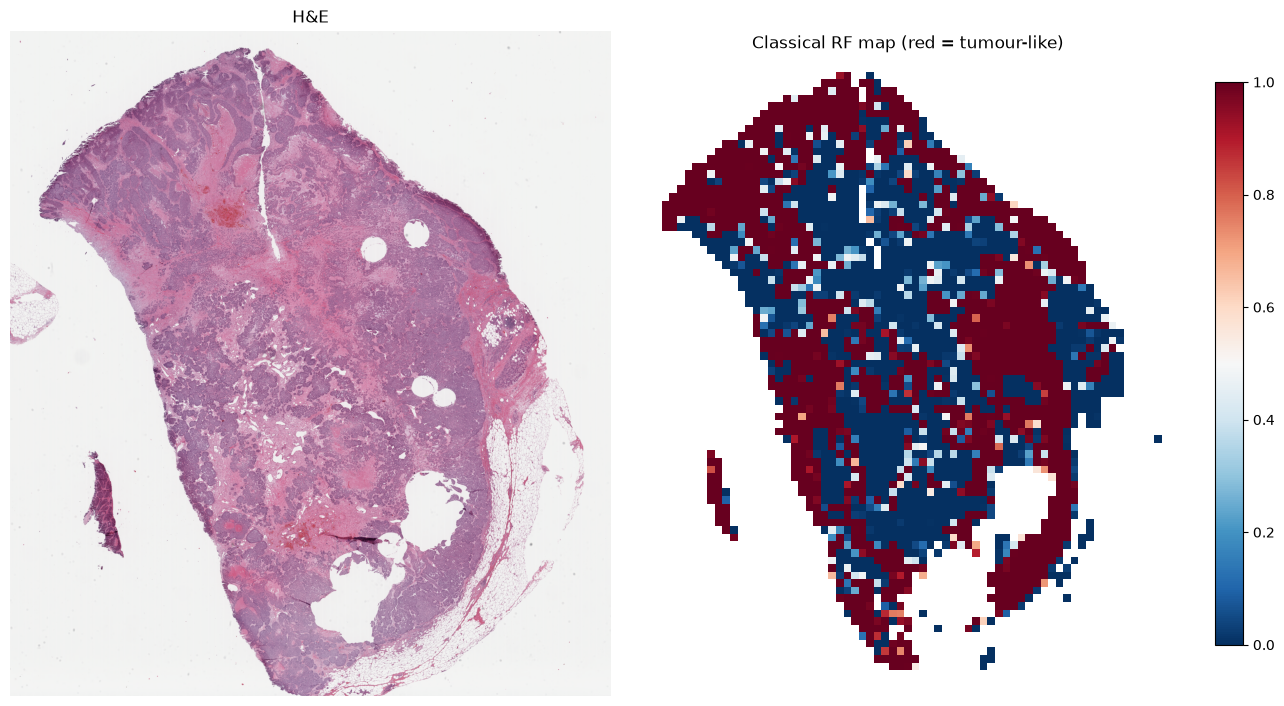

saved -> results/classical_rf_map.png


In [ ]:
# Weak labels from a simple rule: densest third = tumour-like (1),
# sparsest third = stroma/fat (0), middle third = unlabeled (-1)
lo, hi = np.quantile(dens, [0.33, 0.67])
y_weak = np.full(len(dens), -1)
y_weak[dens <= lo] = 0
y_weak[dens >= hi] = 1
train = y_weak >= 0

rf = RandomForestClassifier(n_estimators=300, random_state=0)
rf.fit(feats[train], y_weak[train])
prob = rf.predict_proba(feats)[:, 1]          # tumour-likeness for every tile
print(f"RF trained on {train.sum()} weak-labeled tiles, scored all {len(feats)}")
for name, imp in sorted(zip(FEAT_NAMES, rf.feature_importances_), key=lambda t: -t[1]):
    print(f"  {name:14s} {imp:.3f}")

# Paint each tile's score back onto the slide grid
grid = np.full((H // TILE, W // TILE), np.nan)
for (yy, xx), p in zip(coords, prob):
    grid[yy // TILE, xx // TILE] = p

fig, ax = plt.subplots(1, 2, figsize=(13, 7))
ax[0].imshow(thumb)
ax[0].set_title("H&E")
ax[0].axis("off")
im = ax[1].imshow(grid, cmap="RdBu_r", vmin=0, vmax=1)
ax[1].set_title("Classical RF map (red = tumour-like)")
ax[1].axis("off")
fig.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout()

os.makedirs("results", exist_ok=True)
plt.savefig("results/classical_rf_map.png", dpi=120, bbox_inches="tight")
plt.show()
print("saved -> results/classical_rf_map.png")

## What this shows
- **Every feature is hand-engineered** -careful stain unmixing, morphometry, and texture.
- **The classifier is a Random Forest** 
- Compare `results/classical_rf_map.png` with the **SAMPLER** attention map and the
  **LazySlide** zero-shot map (Stages 2 & 3) to see the progression.

**Reference:** Bankhead et al., *QuPath*, Sci. Rep. 2017 · Gurcan et al., *Histopathological
Image Analysis: A Review*, IEEE RBME 2009 · Ruifrok & Johnston, colour deconvolution, 2001.